# DS1 Decision Tree

Classifies DS1 patients as CKD or not CKD with a single CART decision tree, which splits the patients with yes/no questions on one feature at a time. The only input is the preprocessed train/test split from `Data_Preprocessing.ipynb` (`3_preprocessed_data/`), found through `configs/config.json`. Every choice is made with cross-validation on the training set; the test set is used once, at the end.

| Step | What it does |
|---|---|
| 1 | Load the preprocessed data |
| 2 | Baseline: fully grown tree |
| 3 | Tune depth, leaf size and split criterion |
| 4 | Cost-complexity pruning |
| 5 | Check the scores are stable |
| 6 | Look at the errors on the training folds |
| 7 | Evaluate the final model on the test set |
| 8 | Read the tree: structure and feature importances |
| 9 | Compare all versions |
| 10 | Practical application and related work |

## 1. Load the preprocessed data

We load the preprocessed train and test sets with all 30 features. File paths come from the config, and labels are mapped to 0/1 in the config order (ckd = 0, notckd = 1). A tree splits on thresholds, so feature scaling does not change it; scaled values only make the thresholds harder to read, which step 8 accounts for.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
target = ds["target"]["column"]
class_order = ds["target"]["values"]
RANDOM_STATE = config["training"]["random_state"]
train = pd.read_csv(base / ds["files"]["preprocessed"]["train"])
test = pd.read_csv(base / ds["files"]["preprocessed"]["test"])

X_train, X_test = train.drop(columns=[target]), test.drop(columns=[target])
y_train = train[target].map({c: i for i, c in enumerate(class_order)})
y_test = test[target].map({c: i for i, c in enumerate(class_order)})

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Training classes:", train[target].value_counts().to_dict())

Train: (320, 30) Test: (80, 30)
Training classes: {'ckd': 200, 'notckd': 120}


**Observation:**
- 320 training and 80 test patients with 30 features, no missing values
- Classes are 200 CKD vs 120 not CKD, so macro F1 is used throughout, as it weights both classes equally

## 2. Baseline: fully grown tree

We first train a tree with default settings, which keeps splitting until every leaf is pure. This gives a starting score and shows how much a single unconstrained tree overfits. It is scored with 5-fold stratified cross-validation on the training set, using macro F1, which weights both classes equally.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1_macro")
baseline.fit(X_train, y_train)
print("Fold scores:", scores.round(3))
print(f"Baseline 5-fold macro F1: {scores.mean():.3f} (std {scores.std():.3f})")
print(f"Full tree: depth {baseline.get_depth()}, {baseline.get_n_leaves()} leaves, training accuracy {baseline.score(X_train, y_train):.3f}")

Fold scores: [0.983 0.983 0.967 0.966 0.95 ]
Baseline 5-fold macro F1: 0.970 (std 0.013)
Full tree: depth 5, 9 leaves, training accuracy 1.000


**Observation:**
- The fully grown tree reaches a 5-fold macro F1 of 0.970 (std 0.013)
- It fits the training set perfectly (accuracy 1.000) with only depth 5 and 9 leaves, so the classes separate with a few splits; the gap to cross-validation is the overfitting a pure-leaf tree brings

## 3. Tune depth, leaf size and split criterion

A tree's complexity is controlled by how deep it may grow and how few patients a leaf may hold; the split criterion decides how purity is measured. `class_weight` tests whether reweighting the 200/120 class imbalance helps. We try all 240 combinations with the same 5 folds and keep the one with the best mean macro F1.

| Setting | Values | Meaning |
|---|---|---|
| `max_depth` | 1 to 8, None | Maximum number of questions from root to leaf |
| `min_samples_leaf` | 1, 2, 5, 10, 20 | Fewest patients allowed in a leaf; larger = smoother, less overfitting |
| `criterion` | gini, entropy | Impurity measure used to choose splits |
| `class_weight` | None, balanced | Equal patient weights, or weights inverse to class size |

Best: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 5} -> 5-fold macro F1 0.983 (std 0.018)

Best 5-fold macro F1 per max_depth:
depth
1       0.922
2       0.983
3       0.980
4       0.980
5       0.980
6       0.980
7       0.980
8       0.980
None    0.980

All 240 settings range from 0.893 to 0.983


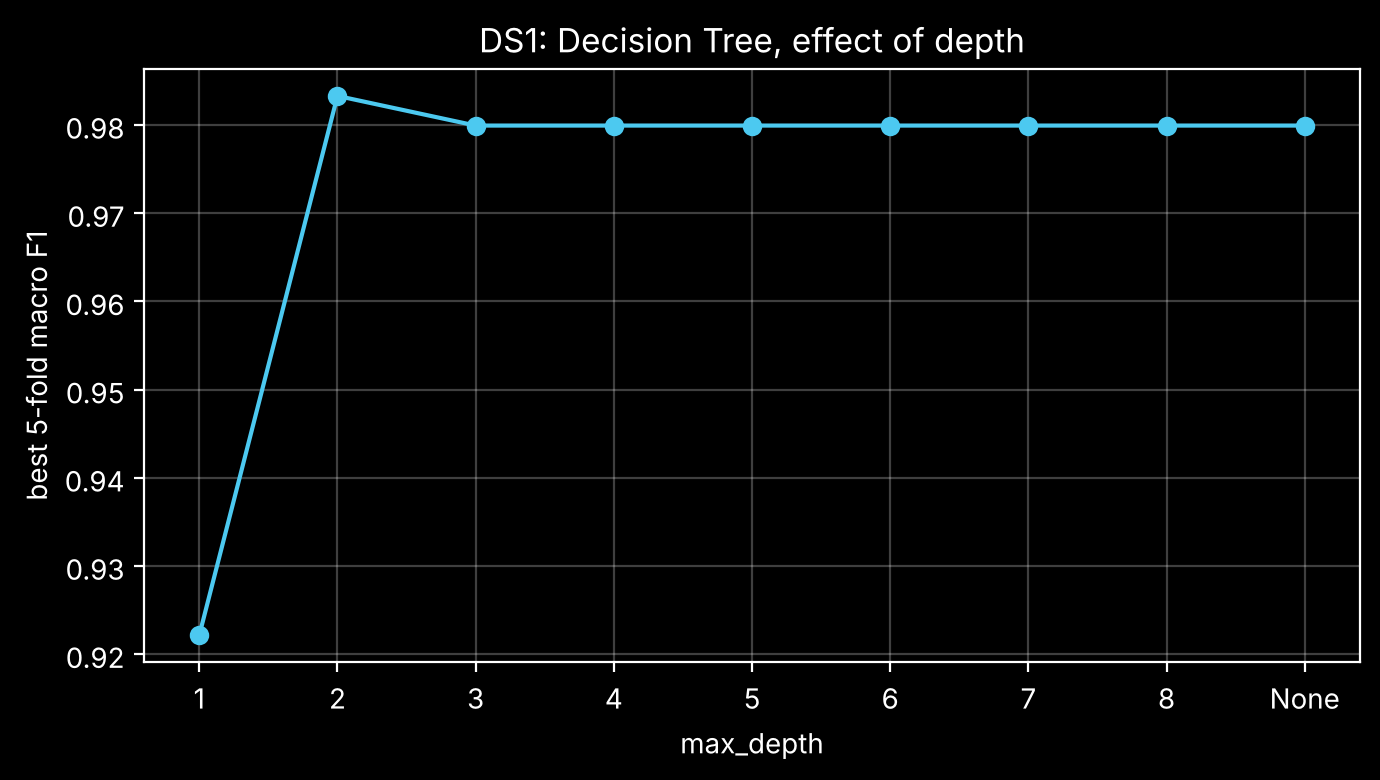

In [3]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {
        "max_depth": [1, 2, 3, 4, 5, 6, 7, 8, None],
        "min_samples_leaf": [1, 2, 5, 10, 20],
        "criterion": ["gini", "entropy"],
        "class_weight": [None, "balanced"],
    },
    cv=cv, scoring="f1_macro",
)
grid.fit(X_train, y_train)
print(f"Best: {grid.best_params_} -> 5-fold macro F1 {grid.best_score_:.3f} "
      f"(std {grid.cv_results_['std_test_score'][grid.best_index_]:.3f})")

res = pd.DataFrame(grid.cv_results_)
res["depth"] = res["param_max_depth"].astype(object).where(res["param_max_depth"].notna(), "None").astype(str)
by_depth = res.groupby("depth")["mean_test_score"].max()
by_depth = by_depth.reindex([str(d) for d in range(1, 9)] + ["None"])
print("\nBest 5-fold macro F1 per max_depth:")
print(by_depth.round(3).to_string())
print(f"\nAll 240 settings range from {res['mean_test_score'].min():.3f} to {res['mean_test_score'].max():.3f}")

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(by_depth.index, by_depth.values, marker="o", color="#4cc9f0")
ax.set_xlabel("max_depth")
ax.set_ylabel("best 5-fold macro F1")
ax.set_title("DS1: Decision Tree, effect of depth")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- Best: depth 2, at least 5 patients per leaf, Gini, balanced class weights (5-fold macro F1 0.983, std 0.018)
- Depth 1 (a single split) scores 0.922; from depth 2 on the score stays at 0.980 to 0.983, so two levels of questions capture almost all the signal
- All 240 settings score between 0.893 and 0.983; the low end comes from very shallow trees or large minimum leaf sizes

## 4. Cost-complexity pruning

Instead of stopping the tree early, CART can grow it fully and then prune back branches whose gain in purity does not pay for their size [1]. The pruning strength `ccp_alpha` is taken from the tree's own pruning path on the training set, and each value is scored with the same 5 folds.

 ccp_alpha   mean    std  leaves
    0.0000 0.9699 0.0126       9
    0.0031 0.9699 0.0126       5
    0.0061 0.9763 0.0230       4
    0.0123 0.9730 0.0204       3
    0.0990 0.9051 0.0239       2

Best ccp_alpha = 0.0061 -> 5-fold macro F1 0.976


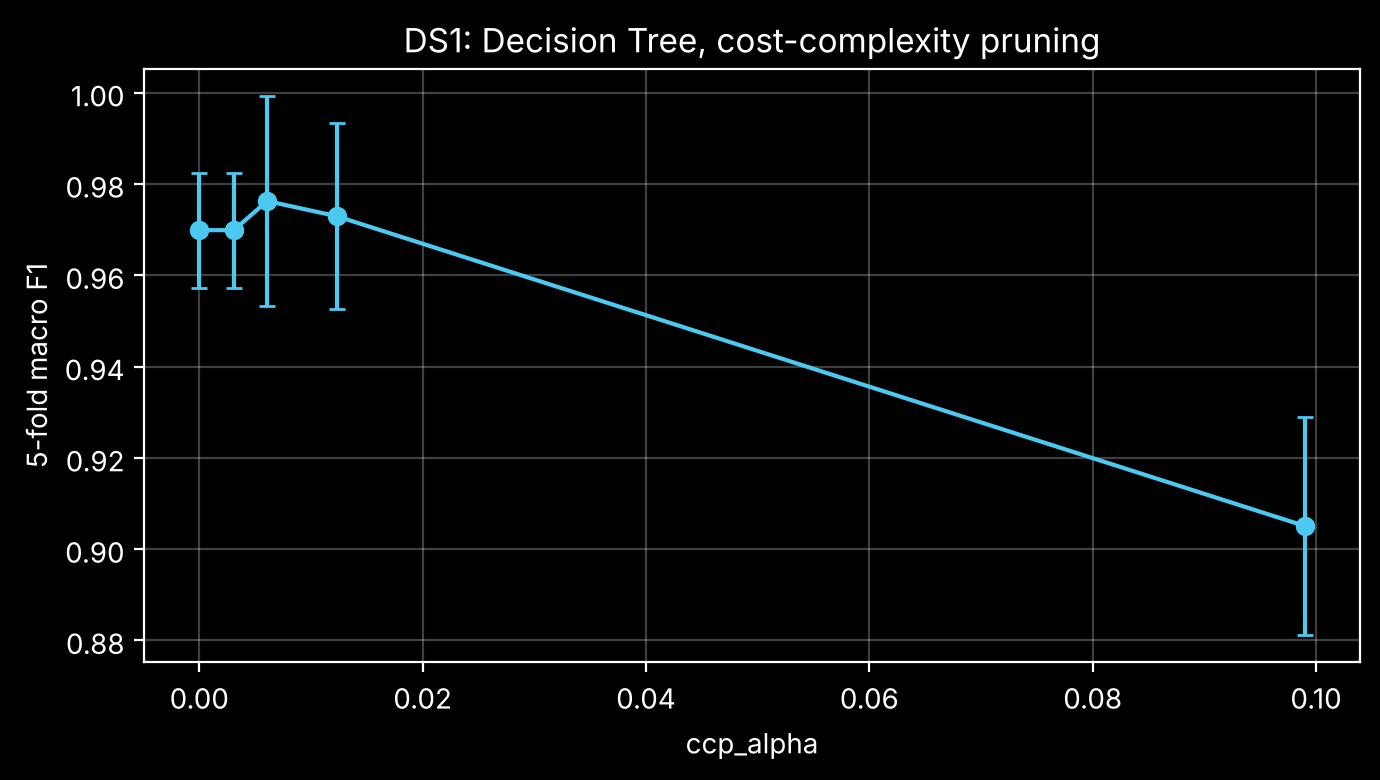

In [4]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(path.ccp_alphas[:-1])  # the last alpha prunes to a single node
alpha_scores = [cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a),
                                X_train, y_train, cv=cv, scoring="f1_macro") for a in alphas]
alpha_df = pd.DataFrame({
    "ccp_alpha": alphas,
    "mean": [s.mean() for s in alpha_scores],
    "std": [s.std() for s in alpha_scores],
    "leaves": [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(X_train, y_train).get_n_leaves() for a in alphas],
})
print(alpha_df.round(4).to_string(index=False))
best_alpha = alpha_df.loc[alpha_df["mean"].idxmax(), "ccp_alpha"]
pruned = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha)
print(f"\nBest ccp_alpha = {best_alpha:.4f} -> 5-fold macro F1 {alpha_df['mean'].max():.3f}")

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(alpha_df["ccp_alpha"], alpha_df["mean"], yerr=alpha_df["std"], marker="o", color="#4cc9f0", capsize=3)
ax.set_xlabel("ccp_alpha")
ax.set_ylabel("5-fold macro F1")
ax.set_title("DS1: Decision Tree, cost-complexity pruning")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- Pruning shrinks the full tree from 9 to 4 leaves at ccp_alpha = 0.0061, raising the 5-fold macro F1 from 0.970 to 0.976
- Pruning further to 2 leaves drops the score to 0.905, so the last useful split must stay

## 5. Check the scores are stable

Steps 3 and 4 each picked their best out of many settings on the same 5 folds, so their scores are a little optimistic. To compare them fairly, we score each version again with 10 different 5-fold splits (50 scores per version). The version with the highest mean becomes the final model.

                         mean    std    min
Baseline (fully grown)  0.978  0.021  0.914
Tuned (grid search)     0.973  0.017  0.916
Pruned (ccp_alpha)      0.979  0.024  0.914

Final model: Pruned (ccp_alpha)


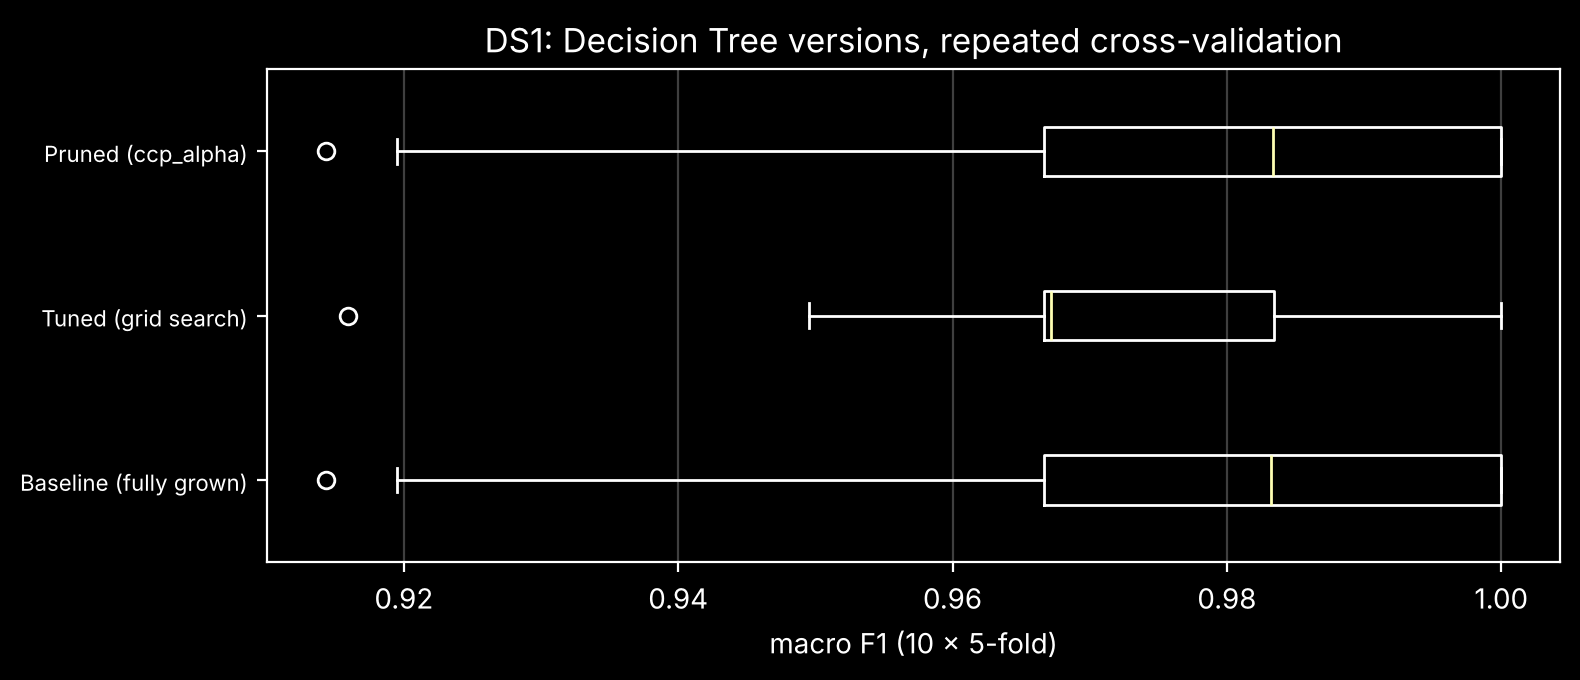

In [5]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
versions = {
    "Baseline (fully grown)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Tuned (grid search)": grid.best_estimator_,
    "Pruned (ccp_alpha)": pruned,
}
repeated = {name: cross_val_score(m, X_train, y_train, cv=rcv, scoring="f1_macro") for name, m in versions.items()}
rep_df = pd.DataFrame({n: [s.mean(), s.std(), s.min()] for n, s in repeated.items()}, index=["mean", "std", "min"]).T
print(rep_df.round(3).to_string())

final_name = rep_df["mean"].idxmax()
final_model = versions[final_name]
print("\nFinal model:", final_name)

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot(list(repeated.values()), orientation="horizontal")
ax.set_yticks(range(1, len(repeated) + 1), list(repeated.keys()), fontsize=8)
ax.set_xlabel("macro F1 (10 x 5-fold)")
ax.set_title("DS1: Decision Tree versions, repeated cross-validation")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- Repeated cross-validation: pruned 0.979, fully grown 0.978, grid-tuned 0.973
- The gaps (at most 0.006) are well inside each version's spread (std 0.017 to 0.024), so the three trees perform about the same; the grid's 0.983 in step 3 was partly a lucky fit to one set of folds
- The pruned tree has the highest mean and becomes the final model; it also has half the leaves of the full tree, so it is easier to read

## 6. Look at the errors on the training folds

The test set is small, so we also look at the 320 out-of-fold predictions of the final model on the training set to see where the tree fails. For each error, we show the predicted CKD probability, which for a tree is the share of CKD patients in the leaf.

In [6]:
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 0]
oof_pred = np.where(oof_proba >= 0.5, 0, 1)
wrong = np.flatnonzero(oof_pred != y_train.values)
print(f"Correct out-of-fold: {len(y_train) - len(wrong)} / {len(y_train)}")
errors = pd.DataFrame({
    "true": [class_order[i] for i in y_train.values[wrong]],
    "predicted": [class_order[i] for i in oof_pred[wrong]],
    "P(ckd)": oof_proba[wrong].round(3),
}, index=wrong)
print(errors.to_string())

Correct out-of-fold: 313 / 320
       true predicted  P(ckd)
41   notckd       ckd   0.987
43      ckd    notckd   0.000
144  notckd       ckd   0.993
150  notckd       ckd   1.000
211  notckd       ckd   0.987
257  notckd       ckd   1.000
280  notckd       ckd   0.987


**Observation:**
- The final model gets 313 of 320 training patients right when they are held out
- 6 of the 7 errors are healthy patients flagged as CKD, the safer error direction for screening; only one CKD patient (row 43) is missed
- The errors are made with near-certain probabilities (0.987 to 1.000, and 0.000 for the missed case): a tree's probability is the leaf's class share, so pure leaves give no warning that a prediction is borderline

## 7. Evaluate the final model on the test set

The final model is refitted on all 320 training patients and tested once on the 80 test patients. The test set played no part in any choice, so this is a fair estimate for new patients. We report accuracy, macro F1, ROC AUC, per-class precision and recall, and the confusion matrix.

Accuracy:  0.9625
Macro F1:  0.9591
ROC AUC:   0.9540

              precision    recall  f1-score   support

         ckd      0.943     1.000     0.971        50
      notckd      1.000     0.900     0.947        30

    accuracy                          0.963        80
   macro avg      0.972     0.950     0.959        80
weighted avg      0.965     0.963     0.962        80



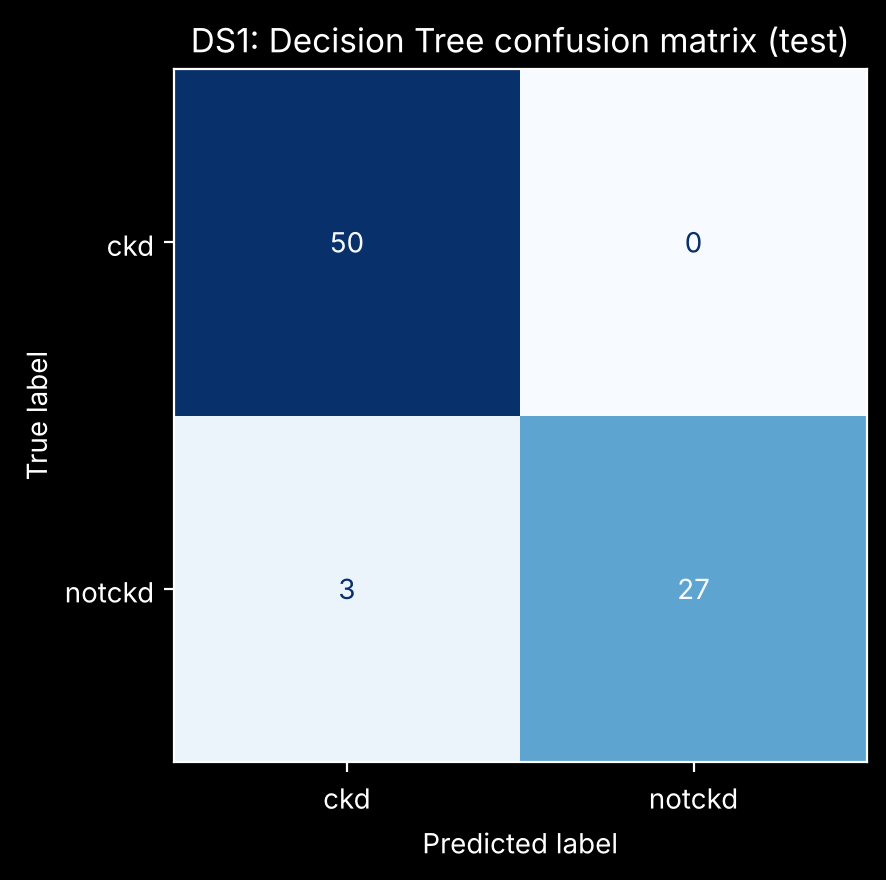

In [7]:
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
p_ckd = final_model.predict_proba(X_test)[:, 0]
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1:  {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_test == 0, p_ckd):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=class_order, digits=3, zero_division=0))

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=class_order).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("DS1: Decision Tree confusion matrix (test)")
plt.tight_layout()
plt.show()

**Observation:**
- On the 80 test patients the final model reaches accuracy 0.963, macro F1 0.959 and ROC AUC 0.954
- All 50 CKD patients are caught (recall 1.000) and 27 of 30 healthy patients are cleared; the 3 errors are all false alarms, matching the pattern in step 6
- The ROC AUC is lower than kNN or Naive Bayes because the 4-leaf tree gives only 4 different probabilities, so it can rank patients only coarsely

## 8. Read the tree: structure and feature importances

A single tree is the most interpretable of the classical models: each prediction is a short list of threshold checks. We print and plot the final tree and its impurity-based feature importances. Thresholds are on the standardised scale from preprocessing (0 = training mean, 1 = one standard deviation above it), not in clinical units.

Depth 3, 4 leaves

|--- hemo <= 0.09
|   |--- class: 0
|--- hemo >  0.09
|   |--- sg <= -0.05
|   |   |--- class: 0
|   |--- sg >  -0.05
|   |   |--- al <= -0.30
|   |   |   |--- class: 1
|   |   |--- al >  -0.30
|   |   |   |--- class: 0

hemo    0.7529
sg      0.2198
al      0.0273


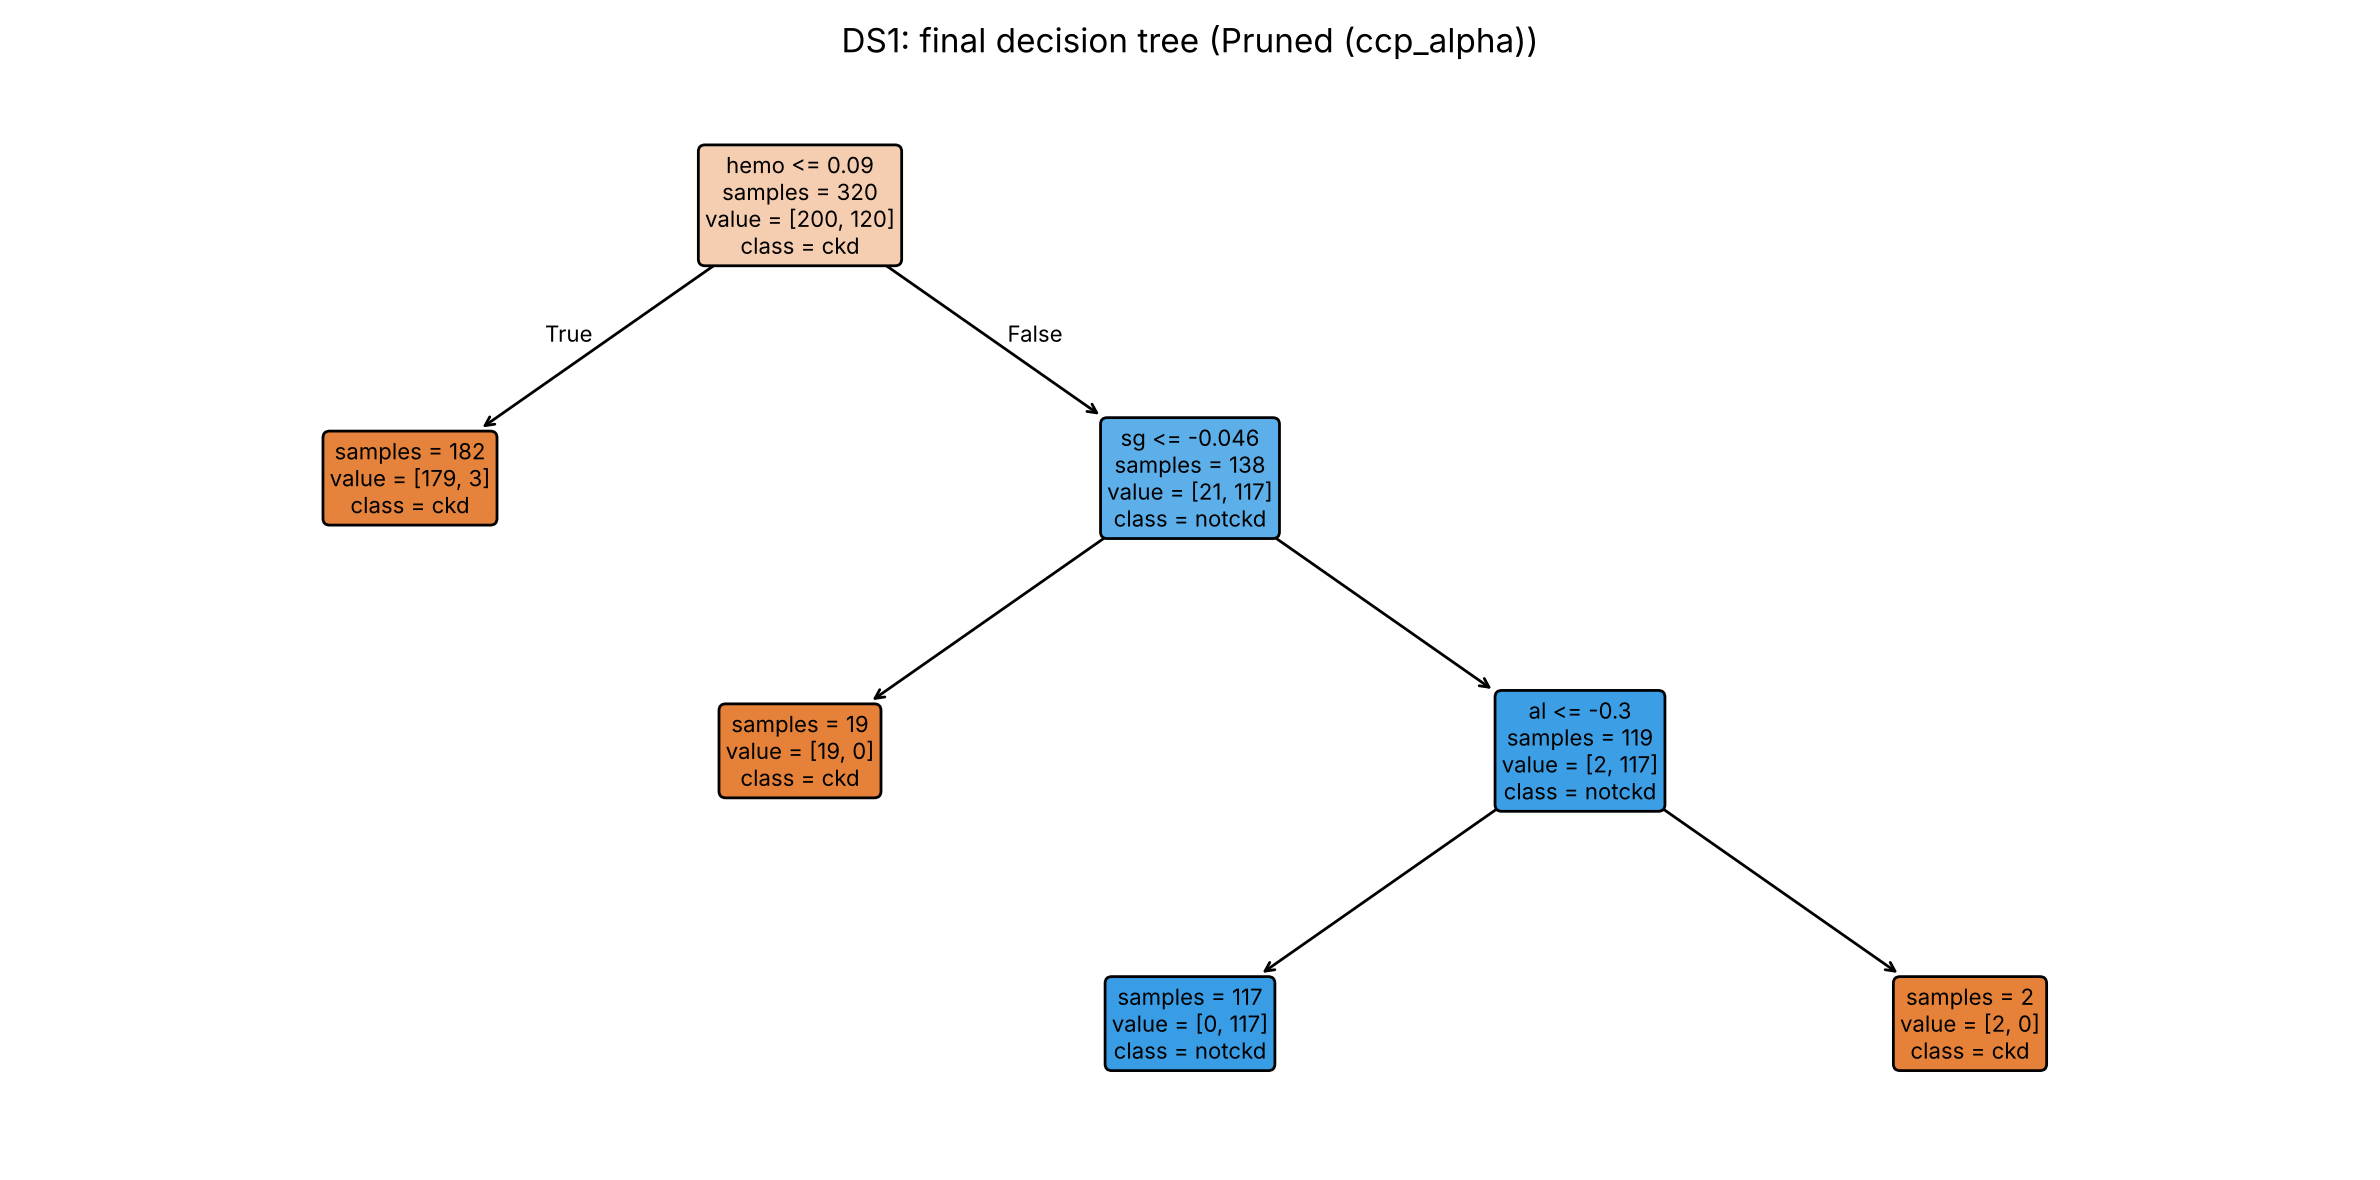

In [8]:
print(f"Depth {final_model.get_depth()}, {final_model.get_n_leaves()} leaves\n")
print(export_text(final_model, feature_names=list(X_train.columns)))

importances = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances[importances > 0].round(4).to_string())

plt.style.use("default")
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(final_model, feature_names=list(X_train.columns), class_names=class_order,
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=8, ax=ax)
ax.set_title(f"DS1: final decision tree ({final_name})")
plt.tight_layout()
plt.show()

**Observation:**
- The final tree has depth 3 and 4 leaves and uses only 3 features: hemoglobin (importance 0.753), specific gravity (0.220) and albumin (0.027)
- Rule: low hemoglobin means CKD; otherwise low urine specific gravity means CKD; otherwise albumin decides
- These are the same anaemia and urine-concentration markers that top the Random Forest importances and the feature-selection ranking, so the tree is consistent with the rest of the project

## 9. Compare all versions

Finally, all versions are put in one table to show what each step added. The final model was chosen on the repeated cross-validation score; test scores are shown for reference only.

In [9]:
rows = []
for name, m in versions.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({
        "version": name,
        "depth": m.get_depth(),
        "leaves": m.get_n_leaves(),
        "repeated CV macro F1": repeated[name].mean(),
        "CV std": repeated[name].std(),
        "test accuracy": accuracy_score(y_test, pred),
        "test macro F1": f1_score(y_test, pred, average="macro"),
    })
print(pd.DataFrame(rows).set_index("version").round(4).to_string())

                        depth  leaves  repeated CV macro F1  CV std  test accuracy  test macro F1
version                                                                                          
Baseline (fully grown)      5       9                0.9776  0.0210         0.9750         0.9730
Tuned (grid search)         2       4                0.9731  0.0169         0.9500         0.9459
Pruned (ccp_alpha)          3       4                0.9792  0.0240         0.9625         0.9591


**Observation:**
- In repeated cross-validation the three trees are within 0.006 of each other; on the test set the fully grown tree scores best (0.973 macro F1), the pruned tree 0.959 and the grid-tuned tree 0.946, a difference of 1 to 2 patients out of 80
- The choice stays with cross-validation, as choosing on the test set would leak it into model selection

**Summary:** A single decision tree on DS1 reaches a repeated 5-fold macro F1 of 0.979 and 0.959 macro F1 on the test set with a 4-leaf, 3-feature tree that misses no CKD patient in the test set. It is less accurate than Random Forest (0.987 test macro F1) and kNN (0.993 repeated CV), but it is the only model whose full decision logic fits in three lines.

## 10. Practical application and related work

**Where a decision tree fits in CKD screening**
- The final tree is a three-question checklist (hemoglobin, then urine specific gravity, then albumin) that a clinician can apply by hand and check against clinical knowledge, which matters where decisions must be explained
- All three inputs are routine, low-cost blood and urine tests
- On the test set it missed no CKD patient, and its errors on the training folds are mostly false alarms, the safer direction for a first-line screen that is followed by confirmatory tests

**Limits seen in this notebook**
- Its probabilities are coarse (4 possible values) and near-certain even when wrong (step 6), so it cannot flag borderline patients; ROC AUC is the lowest of the classical models
- Single trees are unstable: small changes in the training data can change the splits, which is why the three versions swap order between cross-validation and test; Random Forest averages many trees to reduce this
- Thresholds are on the standardised scale; for clinical use they would have to be converted back to units such as g/dL using the training mean and standard deviation

**Related work**
- The tree follows CART [1], which grows binary splits by impurity reduction and introduced cost-complexity pruning (step 4); entropy as a split criterion comes from Quinlan's ID3 line of work [2]
- Random Forest [3] was proposed to reduce the variance of single trees by averaging many of them, which matches its higher scores in `Random_Forest.ipynb`
- The dataset is the UCI Chronic Kidney Disease dataset [4]; the model uses scikit-learn [5]

**References**

[1] L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Wadsworth, 1984.

[2] J. R. Quinlan, "Induction of decision trees," *Machine Learning*, vol. 1, pp. 81-106, 1986. https://doi.org/10.1023/A:1022643204877

[3] L. Breiman, "Random forests," *Machine Learning*, vol. 45, pp. 5-32, 2001. https://doi.org/10.1023/A:1010933404324

[4] L. Rubini, P. Soundarapandian, and P. Eswaran, "Chronic Kidney Disease," UCI Machine Learning Repository, 2015. https://doi.org/10.24432/C5G020

[5] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825-2830, 2011.